In [1]:
import tensorflow as tf
import numpy as np
import warnings
import random
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import layers
warnings.filterwarnings('ignore')

In [2]:
data=np.load('mnist.npz')
x_train,y_train=data['x_train'],data['y_train']
x_test,y_test=data['x_test'],data['y_test']

In [3]:
m,n=np.max(x_train),np.min(x_test)
normalize=m-n
print(f"Max value: {m}")
print(f"Min value: {n}")
x_train,x_test=x_train/normalize,x_test/normalize

Max value: 255
Min value: 0


In [4]:
# --- CHANGE 1: Add channel dimension for CNN ---
# Reshapes (60000, 28, 28) -> (60000, 28, 28, 1)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

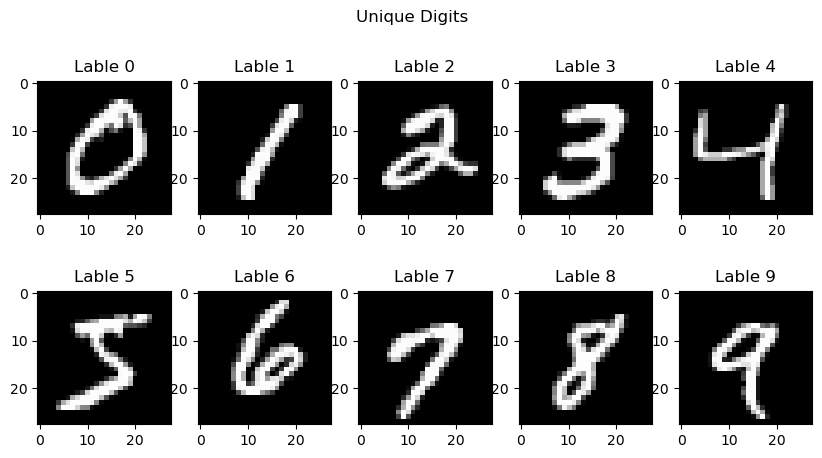

In [5]:
uniqe_val,idx=np.unique(y_train, return_index=True)
fig, ax = plt.subplots(2,5,figsize=(10,5))
for i, lable in enumerate(uniqe_val):
    ax.flat[i].imshow(x_train[idx[i]],cmap='gray')
    ax.flat[i].set_title(f"Lable {lable}")
plt.suptitle("Unique Digits")
plt.show()

In [6]:
# --- CHANGE 2: Replace FNN architecture with CNN (Replaces your Cell [50]) ---
model = keras.Sequential([
    # Convolutional Block 1: detects basic edges & lines
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convolutional Block 2: detects complex shapes & loops
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification Head (Fully Connected / FNN part)
    layers.Flatten(),
    layers.Dropout(0.25),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [7]:
# --- CHANGE 3: Compile model (Updated optimizer from SGD to Adam) ---
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history=model.fit(x_train,y_train,epochs=10,validation_split=0.2,verbose=2)

Epoch 1/10
1500/1500 - 33s - 22ms/step - accuracy: 0.9492 - loss: 0.1623 - val_accuracy: 0.9844 - val_loss: 0.0529
Epoch 2/10


In [53]:
loss,acc=model.evaluate(x_test,y_test,verbose=2)
print(f"Test Accuracy: {acc*100:.2f}%")

313/313 - 1s - 4ms/step - accuracy: 0.9683 - loss: 0.1036
Test Accuracy: 96.83%


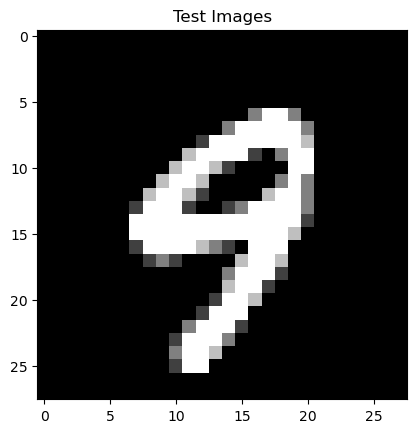

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Pridicted 9


In [55]:
n=random.randint(0,len(x_test)-1)
plt.imshow(x_test[n],cmap='gray')
plt.title("Test Images")
plt.show()
pred=np.argmax(model.predict(np.expand_dims(x_test[n],axis=0))[0])
print("Pridicted",pred)

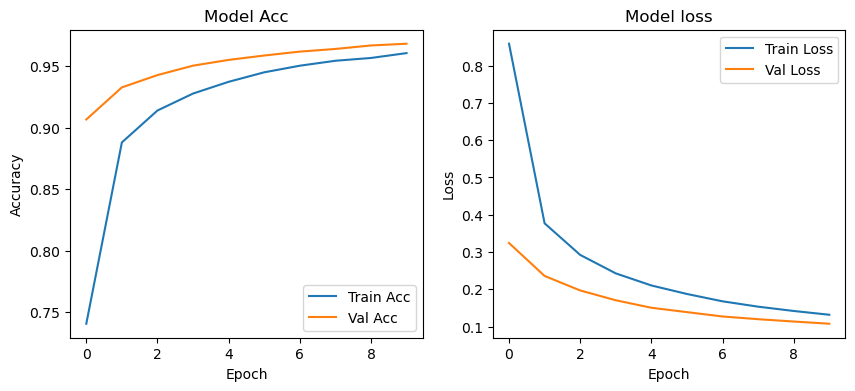

In [56]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label="Train Acc")
plt.plot(history.history['val_accuracy'], label="Val Acc")
plt.title("Model Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'],label="Train Loss")
plt.plot(history.history['val_loss'], label="Val Loss")
plt.title("Model loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()